# Notebook 4: Monitoreo (data drift, concept drift, model drift)
Referencia: steps 301-400. Datos actuales: ventanas de 24 steps (1 step = 1 hora simulada) entre los steps 401 y 743.
Incluye un escenario SIMULADO de fraudes adaptativos para demostrar la detección de degradación.

In [1]:
import os
import shutil
import warnings
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
import mlflow.lightgbm
from dotenv import load_dotenv
from mlflow import MlflowClient
from sklearn.metrics import average_precision_score, precision_score, recall_score, f1_score
from evidently import Report, Dataset, DataDefinition, BinaryClassification
from evidently.presets import DataDriftPreset, ClassificationPreset
from evidently.metrics import MeanValue, RowCount
from evidently.ui.workspace import Workspace
from evidently.sdk.models import PanelMetric
from evidently.sdk.panels import line_plot_panel, counter_panel

warnings.filterwarnings("ignore")  # oculta avisos de versiones
load_dotenv("../.env")
mlflow.set_tracking_uri(os.environ["MLFLOW_TRACKING_URI"])

SEMILLA = 42
OBJETIVO = "isFraud"
FEATURES = [
    "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest",
    "errorBalanceOrig", "errorBalanceDest", "origenVacio", "destinoVacio",
    "hora_dia", "es_transfer",
]
NOMBRE_MODELO = "fraude-paysim-lgbm"
RUTA_WS = os.path.abspath("../monitoring_app/workspace")  # ruta ABSOLUTA: Evidently rechaza rutas con ".."
RUTA_HTML = "../reports/reporte_data_drift_prod.html"
INICIO = datetime(2026, 1, 1)  # reloj simulado: step 1 = 1 de enero de 2026, 00:00
ALERTA_MIN = 0.95  # si AUPRC, precision o recall bajan de este valor, se dispara la alerta
os.makedirs("../reports/figuras", exist_ok=True)
os.makedirs("../monitoring_app", exist_ok=True)

modelo = mlflow.lightgbm.load_model(f"models:/{NOMBRE_MODELO}@produccion")  # modelo productivo
cliente = MlflowClient()
version = cliente.get_model_version_by_alias(NOMBRE_MODELO, "produccion")
umbral = float(cliente.get_run(version.run_id).data.params["umbral_log_odds"])  # umbral guardado en el run

train = pd.read_parquet("../data/processed/full/train.parquet")
val = train[train["step"] > 300]  # steps 301-400: referencia
test = pd.read_parquet("../data/processed/full/test.parquet")  # steps 401-600
prod = pd.read_parquet("../data/processed/full/prod.parquet")  # steps 601-743
print(f"Modelo v{version.version} | umbral {umbral:.4f}")

Modelo v1 | umbral -2.1456


In [2]:
def puntuar(df):
    """Añade el puntaje crudo, la predicción 0/1 y la columna target.

    Args:
        df: DataFrame con las variables del modelo y la columna isFraud.

    Returns:
        Copia del DataFrame con las columnas score, prediction y target.
    """
    d = df.copy()
    d["score"] = modelo.predict(d[FEATURES], raw_score=True)  # log-odds
    d["prediction"] = (d["score"] >= umbral).astype(int)  # decisión con el umbral del modelo
    d["target"] = d[OBJETIVO]  # nombre que usa Evidently
    return d


datos = puntuar(pd.concat([val, test, prod], ignore_index=True))  # steps 301-743
ref = datos[datos["step"] <= 400].sample(30000, random_state=SEMILLA)  # referencia: 30,000 filas de steps 301-400

dd = DataDefinition(  # le dice a Evidently qué es cada columna
    numerical_columns=FEATURES,
    categorical_columns=["target", "prediction"],
    classification=[BinaryClassification(target="target", prediction_labels="prediction", pos_label=1)],
)  # SOLO etiquetas: con probabilidades Evidently usaría corte 0.5 en vez de nuestro umbral
ref_ds = Dataset.from_pandas(ref, data_definition=dd)


def crear_ventanas(ini=401, fin=743, ancho=24, minimo=12):
    """Divide [ini, fin] en ventanas de `ancho` steps y une la última si es muy corta.

    Args:
        ini: primer step.
        fin: último step.
        ancho: steps por ventana (24 = un día simulado).
        minimo: mínimo de steps para que la última ventana sea independiente.

    Returns:
        Lista de tuplas (step_inicial, step_final).
    """
    inicios = list(range(ini, fin + 1, ancho))
    if fin - inicios[-1] + 1 < minimo:
        inicios.pop()  # la última ventana es muy corta: se une a la anterior
    return [(a, inicios[k + 1] - 1 if k + 1 < len(inicios) else fin) for k, a in enumerate(inicios)]


ventanas = crear_ventanas()
print(len(ventanas), "ventanas | primera:", ventanas[0], "| última:", ventanas[-1])

14 ventanas | primera: (401, 424) | última: (713, 743)


In [3]:
prod_df = datos[datos["step"] > 600]  # todo el periodo de producción
reporte = Report([DataDriftPreset(columns=FEATURES)], include_tests=False)
snap = reporte.run(Dataset.from_pandas(prod_df, data_definition=dd), ref_ds)  # producción vs referencia
snap.save_html(RUTA_HTML)  # entregable: Report HTML
print("Reporte HTML:", os.path.getsize(RUTA_HTML) // 1024, "KB")

filas = []
for m in snap.dict()["metrics"]:
    config = m["config"]
    if str(config.get("type", "")).endswith("ValueDrift"):  # un puntaje de drift por variable
        filas.append({"variable": config["column"], "metodo": config.get("method"),
                      "puntaje_drift": float(m["value"]), "umbral": config.get("threshold")})
    if str(config.get("type", "")).endswith("DriftedColumnsCount"):
        resumen_drift = m["value"]  # {'count': ..., 'share': ...}

tabla_drift = pd.DataFrame(filas).sort_values("puntaje_drift", ascending=False)
print(tabla_drift.round(4).to_string(index=False))
print("Variables con drift:", resumen_drift)

Reporte HTML: 4312 KB
        variable                        metodo  puntaje_drift  umbral
   oldbalanceOrg Wasserstein distance (normed)         0.2965     0.1
errorBalanceOrig Wasserstein distance (normed)         0.1167     0.1
        hora_dia Wasserstein distance (normed)         0.1080     0.1
     origenVacio       Jensen-Shannon distance         0.0868     0.1
errorBalanceDest Wasserstein distance (normed)         0.0854     0.1
  newbalanceDest Wasserstein distance (normed)         0.0786     0.1
  newbalanceOrig Wasserstein distance (normed)         0.0730     0.1
          amount Wasserstein distance (normed)         0.0717     0.1
  oldbalanceDest Wasserstein distance (normed)         0.0587     0.1
    destinoVacio       Jensen-Shannon distance         0.0520     0.1
     es_transfer       Jensen-Shannon distance         0.0314     0.1
Variables con drift: {'count': 3.0, 'share': 0.2727272727272727}


In [4]:
def metricas_ventana(w):
    """Calcula las métricas del modelo en una ventana de datos.

    Args:
        w: DataFrame con score, prediction y target.

    Returns:
        Diccionario con filas, fraudes, prevalencia, AUPRC, precision, recall y F1.
    """
    return {
        "filas": len(w), "fraudes": int(w["target"].sum()), "prevalencia": w["target"].mean(),
        "auprc": average_precision_score(w["target"], w["score"]),  # sobre el puntaje crudo
        "precision": precision_score(w["target"], w["prediction"], zero_division=0),
        "recall": recall_score(w["target"], w["prediction"], zero_division=0),
        "f1": f1_score(w["target"], w["prediction"], zero_division=0),
    }


filas = []
for a, b in ventanas:
    w = datos[(datos["step"] >= a) & (datos["step"] <= b)]
    filas.append({"steps": f"{a}-{b}", **metricas_ventana(w)})
rend = pd.DataFrame(filas)
rend["alerta"] = rend[["auprc", "precision", "recall"]].min(axis=1) < ALERTA_MIN  # True si alguna métrica baja del mínimo
print(rend.round(4).to_string(index=False))

  steps  filas  fraudes  prevalencia  auprc  precision  recall     f1  alerta
401-424  89600      308       0.0034 1.0000     1.0000  1.0000 1.0000   False
425-448   6555      250       0.0381 1.0000     1.0000  1.0000 1.0000   False
449-472   7004      248       0.0354 1.0000     1.0000  1.0000 1.0000   False
473-496  10442      232       0.0222 1.0000     0.9957  1.0000 0.9978   False
497-520  10592      266       0.0251 1.0000     1.0000  1.0000 1.0000   False
521-544  24301      244       0.0100 1.0000     1.0000  1.0000 1.0000   False
545-568  18840      262       0.0139 1.0000     1.0000  1.0000 1.0000   False
569-592  19110      258       0.0135 0.9989     1.0000  0.9961 0.9981   False
593-616  13524      256       0.0189 1.0000     1.0000  1.0000 1.0000   False
617-640   5116      268       0.0524 1.0000     1.0000  1.0000 1.0000   False
641-664   5855      268       0.0458 1.0000     1.0000  0.9963 0.9981   False
665-688  15704      234       0.0149 1.0000     1.0000  1.0000 1

In [5]:
filas = []
for a, b in ventanas:
    w = datos[(datos["step"] >= a) & (datos["step"] <= b)]
    senal = (w["errorBalanceOrig"].abs() < 0.01) & (w["oldbalanceOrg"] > 0)  # señal clave: saldo de origen coherente
    filas.append({
        "steps": f"{a}-{b}",
        "P(señal|fraude)": senal[w["target"] == 1].mean(),  # frecuencia de la señal entre fraudes
        "P(señal|normal)": senal[w["target"] == 0].mean(),  # frecuencia de la señal entre normales
        "prevalencia": w["target"].mean(),
    })
conc = pd.DataFrame(filas)
print(conc.round(4).to_string(index=False))

  steps  P(señal|fraude)  P(señal|normal)  prevalencia
401-424           1.0000           0.1029       0.0034
425-448           0.9840           0.1159       0.0381
449-472           1.0000           0.1106       0.0354
473-496           1.0000           0.0967       0.0222
497-520           1.0000           0.0976       0.0251
521-544           1.0000           0.0959       0.0100
545-568           0.9924           0.1090       0.0139
569-592           0.9922           0.1093       0.0135
593-616           1.0000           0.1294       0.0189
617-640           0.9925           0.1244       0.0524
641-664           0.9851           0.0959       0.0458
665-688           0.9915           0.0970       0.0149
689-712           0.9928           0.1173       0.0229
713-743           0.9835           0.1777       0.1750


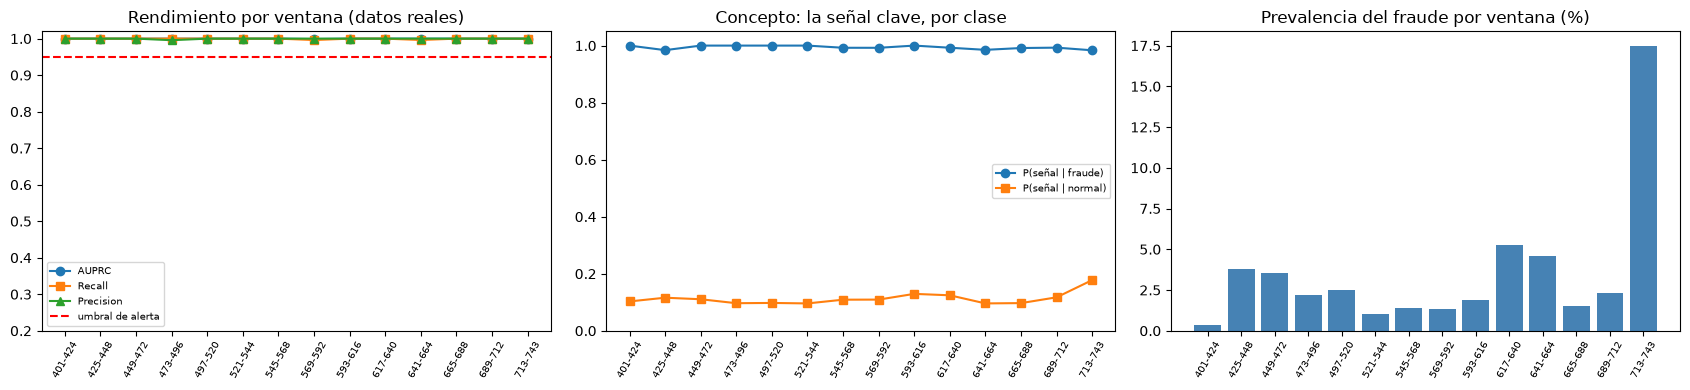

In [6]:
fig, ejes = plt.subplots(1, 3, figsize=(17, 4))
x = list(range(len(rend)))
ejes[0].plot(x, rend["auprc"], marker="o", label="AUPRC")
ejes[0].plot(x, rend["recall"], marker="s", label="Recall")
ejes[0].plot(x, rend["precision"], marker="^", label="Precision")
ejes[0].axhline(ALERTA_MIN, color="red", linestyle="--", label="umbral de alerta")
ejes[0].set_ylim(0.2, 1.02)
ejes[0].set_title("Rendimiento por ventana (datos reales)")
ejes[0].legend(fontsize=7)
ejes[1].plot(x, conc["P(señal|fraude)"], marker="o", label="P(señal | fraude)")
ejes[1].plot(x, conc["P(señal|normal)"], marker="s", label="P(señal | normal)")
ejes[1].set_ylim(0, 1.05)
ejes[1].set_title("Concepto: la señal clave, por clase")
ejes[1].legend(fontsize=7)
ejes[2].bar(x, conc["prevalencia"] * 100, color="steelblue")
ejes[2].set_title("Prevalencia del fraude por ventana (%)")
for ax in ejes:
    ax.set_xticks(x)
    ax.set_xticklabels(rend["steps"], rotation=60, fontsize=7)  # una etiqueta por ventana
plt.tight_layout()
fig.savefig("../reports/figuras/monitoreo_real.png", dpi=150, bbox_inches="tight")
plt.show()

rend.to_csv("../reports/monitoreo_real.csv", index=False)  # evidencia para el README
conc.to_csv("../reports/monitoreo_concepto.csv", index=False)

In [7]:
shutil.rmtree(RUTA_WS, ignore_errors=True)  # reconstruye el workspace desde cero
ws = Workspace.create(RUTA_WS)  # crea la carpeta donde Evidently guarda proyectos y snapshots


def pm(leyenda, metrica, **etiquetas):
    """Atajo para definir una serie de un panel (nombre de la métrica y sus etiquetas)."""
    return PanelMetric(legend=leyenda, metric=metrica, metric_labels=etiquetas)


def configurar_dashboard(ws, proyecto):
    """Crea los paneles del dashboard y elimina ids duplicados del tab.

    Args:
        ws: workspace de Evidently.
        proyecto: proyecto al que se agregan los paneles.
    """
    d = proyecto.dashboard
    d.add_panel(counter_panel("Features con drift (última ventana)", [pm("share", "DriftedColumnsCount", value_type="share")], size="half"), tab="Resumen")
    d.add_panel(line_plot_panel("Proporción de features con drift", [pm("share", "DriftedColumnsCount", value_type="share")], size="half"), tab="Resumen")
    d.add_panel(line_plot_panel("Rendimiento del modelo (model drift)", [pm("Precision", "Precision"), pm("Recall", "Recall"), pm("F1", "F1Score")]), tab="Resumen")
    d.add_panel(line_plot_panel("Tasa de fraude real (prior drift)", [pm("fraude", "MeanValue", column="target")], size="half"), tab="Resumen")
    d.add_panel(line_plot_panel("Transacciones por ventana", [pm("filas", "RowCount")], size="half"), tab="Resumen")
    dm = ws.get_dashboard(proyecto.id)
    for tab in dm.tabs:
        tab.panels = list(dict.fromkeys(tab.panels))  # quita ids repetidos conservando el orden
    ws.save_dashboard(proyecto.id, dm)


def agregar_ventanas(ws, proyecto, fuente):
    """Calcula un snapshot de Evidently por ventana y lo agrega al proyecto.

    Args:
        ws: workspace de Evidently.
        proyecto: proyecto destino.
        fuente: función (step_inicial, step_final, índice) que devuelve el DataFrame de la ventana.
    """
    for k, (a, b) in enumerate(ventanas):
        w = fuente(a, b, k)
        if w["target"].nunique() < 2:  # sin las dos clases, las métricas no se pueden calcular
            continue
        r = Report([DataDriftPreset(columns=FEATURES), ClassificationPreset(), MeanValue(column="target"), RowCount()], include_tests=False)
        s = r.run(Dataset.from_pandas(w, data_definition=dd), ref_ds,
                  timestamp=INICIO + timedelta(hours=a - 1), tags=[f"steps {a}-{b}"])  # fecha simulada de la ventana
        ws.add_run(proyecto.id, s)


p1 = ws.create_project("Fraude PaySim: monitoreo (datos reales)", "Ventanas de 24 steps (1 step = 1 hora simulada) vs referencia steps 301-400.")
configurar_dashboard(ws, p1)
agregar_ventanas(ws, p1, lambda a, b, k: datos[(datos["step"] >= a) & (datos["step"] <= b)])
print("Proyecto de datos reales listo")

Proyecto de datos reales listo


In [8]:
def simular_adaptativo(w, prob, rng):
    """Hace que una fracción `prob` de los fraudes imite a una transacción normal (el origen no se debita).

    Args:
        w: DataFrame de una ventana con score, prediction y target.
        prob: fracción de fraudes que se modifica (0 a 1).
        rng: generador aleatorio de numpy.

    Returns:
        DataFrame con las variables modificadas y re-puntuado con el modelo.
    """
    d = w.copy()
    idx = d.index[d["target"] == 1]  # filas fraudulentas
    elegidos = idx[rng.random(len(idx)) < prob]  # las que se adaptan
    d.loc[elegidos, "newbalanceOrig"] = d.loc[elegidos, "oldbalanceOrg"]  # el saldo de origen no se debita
    d["errorBalanceOrig"] = d["newbalanceOrig"] + d["amount"] - d["oldbalanceOrg"]  # se recalcula la variable derivada
    return puntuar(d.drop(columns=["score", "prediction", "target"]))  # el modelo vuelve a predecir


n_rest = sum(1 for _, b in ventanas if b > 600)  # ventanas del periodo de producción
rampa = [0] * (len(ventanas) - n_rest) + list(np.linspace(0.15, 0.9, n_rest))  # 0 en test; de 15% a 90% en producción
probs = [0.0 if b <= 600 else float(p) for (_, b), p in zip(ventanas, rampa)]


def fuente_sim(a, b, k):
    """Devuelve la ventana k con el escenario simulado aplicado."""
    return simular_adaptativo(datos[(datos["step"] >= a) & (datos["step"] <= b)], probs[k], np.random.default_rng(SEMILLA + k))


filas = []
for k, (a, b) in enumerate(ventanas):
    filas.append({"steps": f"{a}-{b}", "frac_fraudes_adaptados": probs[k], **metricas_ventana(fuente_sim(a, b, k))})
sim = pd.DataFrame(filas)
sim["alerta"] = sim[["auprc", "precision", "recall"]].min(axis=1) < ALERTA_MIN
print(sim.round(4).to_string(index=False))
sim.to_csv("../reports/monitoreo_simulado.csv", index=False)

p2 = ws.create_project("Fraude PaySim: escenario SIMULADO (fraudes adaptativos)", "SIMULACION: una fracción creciente de fraudes imita saldos de origen sin debitar.")
configurar_dashboard(ws, p2)
agregar_ventanas(ws, p2, fuente_sim)
print("Proyecto simulado listo")

  steps  frac_fraudes_adaptados  filas  fraudes  prevalencia  auprc  precision  recall     f1  alerta
401-424                    0.00  89600      308       0.0034 1.0000     1.0000  1.0000 1.0000   False
425-448                    0.00   6555      250       0.0381 1.0000     1.0000  1.0000 1.0000   False
449-472                    0.00   7004      248       0.0354 1.0000     1.0000  1.0000 1.0000   False
473-496                    0.00  10442      232       0.0222 1.0000     0.9957  1.0000 0.9978   False
497-520                    0.00  10592      266       0.0251 1.0000     1.0000  1.0000 1.0000   False
521-544                    0.00  24301      244       0.0100 1.0000     1.0000  1.0000 1.0000   False
545-568                    0.00  18840      262       0.0139 1.0000     1.0000  1.0000 1.0000   False
569-592                    0.00  19110      258       0.0135 0.9989     1.0000  0.9961 0.9981   False
593-616                    0.15  13524      256       0.0189 0.9589     1.0000  0.

In [9]:
mlflow.set_experiment("monitoreo-fraude")
with mlflow.start_run(run_name="monitoreo_ventanas"):
    for k, fila in rend.iterrows():  # una entrada por ventana, con el índice de ventana como step
        mlflow.log_metrics({m: float(fila[m]) for m in ["auprc", "precision", "recall", "f1", "prevalencia"]}, step=int(k))
    mlflow.log_metric("share_features_con_drift_prod", float(resumen_drift["share"]))
    mlflow.log_param("ventanas", len(ventanas))
    mlflow.log_param("alerta_min", ALERTA_MIN)
    mlflow.log_artifact(RUTA_HTML)  # reporte HTML de drift
    mlflow.log_artifact("../reports/monitoreo_real.csv")
    mlflow.log_artifact("../reports/figuras/monitoreo_real.png")
print("Monitoreo registrado en MLflow")

2026/10/17 23:53:20 INFO mlflow.tracking.fluent: Experiment with name 'monitoreo-fraude' does not exist. Creating a new experiment.


🏃 View run monitoreo_ventanas at: https://dagshub.com/EduardoCardoza/fraud-detection-mle3.mlflow/#/experiments/2/runs/c66a256db7f848f0bdd401599cdbf9d3
🧪 View experiment at: https://dagshub.com/EduardoCardoza/fraud-detection-mle3.mlflow/#/experiments/2
Monitoreo registrado en MLflow
